# Measure frontier schedules against their evidence

**Question:** Does a positive paired objective difference mean the frozen policy produces useful production schedules?

**Level 4.** Proposed method evidence.

**Prerequisites:** Read the frontier mechanics and training-record lessons first. **Estimated time:** 60 minutes.

## Objectives

This worked analysis follows the frozen policy from its sealed synthetic test to the thirteen declared product cases. You will verify the training and evaluation identities, check the validation rows that selected checkpoints, calculate the predeclared seed-cluster intervals, compare paired product outcomes, and inspect where coverage collapses. The notebook keeps every partial and failed case in its denominator. It uses only sanitized aggregate case records: generated graphs, block features, schedules from licensed MineLib instances, and model weights are not included. By the end, you should be able to explain why a favorable mean difference can coexist with an unusable median schedule, how the comparator changes interpretation, and which conclusions belong to this fixed benchmark rather than a wider mine population.

## Setup

Run from the repository root with the exact packages shown below. The notebook imports the same PhaseFlow summary, split-validation, and seed-cluster bootstrap functions used by the evaluation pipeline. It does not train or reload the actor and cannot reopen any test split. The compact dataset records hashes of the original external receipts, frozen commits, split identities, and one row per synthetic seed or product case. A fresh run recalculates every table and plot from those committed rows. If a digest or identity disagrees, stop and resolve provenance before discussing the numbers; visually plausible output is not a substitute for a matched experiment.

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2 torch==2.14.1
```

### Runtime pins

The next cell reports the installed versions before reading evidence.

In [1]:
# Report exact notebook and solver pins before processing evidence.
import importlib.metadata

versions = {name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib", "torch")}
print(versions)


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2', 'torch': '2.14.1'}


### Product APIs and records

Import the reusable PhaseFlow provenance, summary and uncertainty functions; do not reimplement them.

In [2]:
# Resolve the repository root and import plotting dependencies.
from pathlib import Path
import json, sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter inside the PhaseFlow checkout.")
sys.path.insert(0, str(ROOT / "data-pipeline"))


### Load and validate the frozen evidence

The next cell imports the reusable analysis APIs, loads the committed aggregate and checks its full row contract.

In [3]:
# Import the analysis APIs and validate the committed summary.
from pipeline.model.frontier_evaluation import seed_clustered_interval, target_version
from pipeline.model.frontier_evidence import (
    summarize_case_rows,
    validate_frontier_diagnostic,
    validate_frontier_evaluation_summary,
)
from pipeline.model.frontier_policy import FrontierInstance, feasible_frontier, validate_schedule
from pipeline.model.frontier_ppo import (
    FrontierPolicyEnv,
    MaskedGraphActorCritic,
    select_ensemble_action,
    replay_frontier_ensemble,
)
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256

DATA = json.loads((ROOT / "notebooks/data/frontier-evaluation-summary.json").read_text(encoding="utf-8"))
SUMMARY_AUDIT = validate_frontier_evaluation_summary(DATA)
print(
    {
        "product_version": target_version(ROOT),
        "evaluation_commit": DATA["evaluation_source_commit"],
        "summary_audit": SUMMARY_AUDIT,
    }
)


{'product_version': '0.12.000', 'evaluation_commit': '4a106eae922c696856f4aff6f977d0f881d6c29a', 'summary_audit': {'synthetic_cases': 500, 'product_cases': 13, 'family': ['funnel'], 'empty_synthetic_schedules': 277, 'unique_product_case_ids': 13, 'declared_receipt_hashes': {'product_case_sha256': 'd023db6d67823ee189e944b16d0b9ed0e0aaba302d6754a127beb3ac91916bb2', 'synthetic_test_sha256': '2974b8ead9dfd81c0808e30fee5dfe3a2f148d5bdb984352a1b5880e48fd8f7d'}}}


## Data

The synthetic test contains one observation for each seed in a new, family-disjoint 500-case sample. Each row is a distinct funnel-family seed and includes graph size, independent validator status, assignments, normalized NPV, actual greedy TopoSort NPV, paired difference, and both coverage fractions. Product rows represent the thirteen registry entries. They contain aggregate NPV, bound gap, runtime, coverage, status, explicit failure reason, and paired baseline outcomes. MineLib values are limited to permitted period aggregates; no per-block vector is present. MineLib is attributed to Espinoza, Goycoolea, Moreno and Newman, DOI 10.1007/s10479-012-1258-3; the canonical site is https://mansci-web.uai.cl/minelib/. Its licence text remains unverified, so the project treats downloads as academic access with redistribution not granted. Synthetic twins are generated by PhaseFlow under MIT; that repository licence does not change MineLib terms. The record also binds the five checkpoint hashes, training and evaluation source commits, feature contract, split, case index, and hashes of both source receipts. These are generated development instances and a fixed research benchmark, not customer or operating-mine data.

Source attribution: synthetic twins are generated by the PhaseFlow team and the repository code is MIT licensed. Published cases are MineLib (Espinoza, Goycoolea, Moreno and Newman, https://doi.org/10.1007/s10479-012-1258-3; catalog https://mansci-web.uai.cl/minelib/). MineLib's licence text is unverified; access is treated as academic download with redistribution not granted. Only permitted aggregates appear here.

## Method

First validate the frozen split and training-selection record with the product API. The 200 validation rows helped select checkpoints, so their summary is a post-selection diagnostic. Next calculate the test mean, median, coverage and bootstrap interval by seed cluster. The estimator averages repeated rows within a seed before resampling seeds. In this held-out sample there is one row per seed, but calling the shared API preserves the protocol if a future manifest contains repeated family rows. Do not resample blocks: they share one generated graph and are not independent experimental units. Keep zero assignments as observed outcomes; dropping them would answer a different question.

The actor scores legal action $a$ from block embedding $h_i$ and current schedule state $s$. For member $k$, its logit is $\ell_{k,a}=f_{\theta_k}(h_a,s)$. The ensemble averages the five frozen members, $\bar\ell_a=K^{-1}\sum_{k=1}^{K}\ell_{k,a}$, for block and stop actions. A Boolean mask replaces inadmissible block scores with $-\infty$; deterministic selection is $a^*=\arg\max_{a\in\mathcal A(s)}\bar\ell_a$. The hard mask preserves the encoded constraints at each step, while a separate validator recomputes assignments, resource loads, and discounted objective. The hypothesis is that conditioning logits on residual resources and schedule state improves choices over a fixed greedy ordering when constraints change across periods. It does not imply full extraction or global optimality; the measured test below rejects a useful-coverage interpretation for this frozen policy.

For each test case, let $Y_i$ be normalized policy NPV and $G_i$ the greedy value on the same graph. The paired difference is $D_i=Y_i-G_i$. The mean of $D_i$ and its cluster-bootstrap interval describe the value-only contrast under this generator. They do not measure usefulness by themselves. Compare them with the distribution of $Y_i$, assignments, and coverage. A policy returning zero is economically different from a high-coverage schedule even if both satisfy every hard constraint.

For product case $c$ and comparator $m$, count a win when $V_{frontier,c}>V_{m,c}$ on the identical case and objective. Report the denominator next to the count and keep failed policy cases out of the paired count while retaining them in the overall case denominator. These thirteen cases are a fixed suite, not random draws from a target population, so a win fraction is descriptive. Comparators can differ in solver effort; runtime, bound gap, and coverage provide context rather than a single ranking.

$$D_i=Y_i-G_i$$

$$\widehat{\Delta}=S^{-1}\sum_{s=1}^{S}\overline{D}_s$$

Each seed contributes one cluster; repeated rows are averaged by the shared estimator before resampling.

### A bounded policy-mechanics fixture

This four-block DAG uses randomly initialized weights to demonstrate the public actor, action mask, ensemble replay and independent validator. It is not a trained checkpoint, a test observation, a benchmark result, or performance evidence.

In [4]:
# Define a deterministic fixture separate from the frozen test ledger.
instance = FrontierInstance(
    values=np.array([7.0, 5.0, 4.0, 3.0]),
    resources=np.array([[1, 1], [1, 0], [0, 1], [1, 1]], dtype=float),
    predecessors=((), (0,), (0,), (1, 2)),
    capacities=np.array([[2, 2], [2, 2]], dtype=float),
    discount_rate=0.05,
)
node_features = np.array([[7, 1, 1], [5, 1, 0], [4, 0, 1], [3, 1, 1]], dtype=np.float32)
tonnage = np.array([10, 8, 7, 5], dtype=float)
print(
    {
        "blocks": len(instance.values),
        "periods": len(instance.capacities),
        "dag_edges": sum(map(len, instance.predecessors)),
    }
)


{'blocks': 4, 'periods': 2, 'dag_edges': 4}


Precedence and two-resource feasibility come from the canonical instance. The two stop actions are separate from block indices. Inspect the initial mask before asking the actor to score it.

In [5]:
# Inspect legal actions at the initial state.
env = FrontierPolicyEnv(instance, node_features)
observation = env.observation()
engine_frontier = feasible_frontier(instance, (), 0)
legal_actions = np.flatnonzero(observation.admissible.numpy()).tolist()
print(
    {
        "legal_block_indices": [a for a in legal_actions if a < len(instance.values)],
        "independent_feasible_frontier": engine_frontier,
        "stop_period_index": len(instance.values),
        "stop_schedule_index": len(instance.values) + 1,
        "state_features": observation.state_features.tolist(),
    }
)


{'legal_block_indices': [0], 'independent_feasible_frontier': (0,), 'stop_period_index': 4, 'stop_schedule_index': 5, 'state_features': [0.0, 1.0, 1.0, 0.0, 0.25]}


The two-member ensemble executes only the inference path. Fixed initialization makes this lesson reproducible; because weights were not trained, its choices have no scientific or operational interpretation.

In [6]:
# Instantiate reproducible mechanics-only members; load no checkpoint.
import torch

torch.manual_seed(20261112)
models = [
    MaskedGraphActorCritic(node_feature_count=3, state_feature_count=env.state_feature_count)
    for _ in range(2)
]
for model in models:
    model.set_feature_normalizer([0, 0, 0], [1, 1, 1])
    model.eval()
print({"members": len(models), "trained_checkpoint_loaded": False, "device": "cpu"})


{'members': 2, 'trained_checkpoint_loaded': False, 'device': 'cpu'}


Average member logits first, then apply the mask so inadmissible actions receive negative infinity. The explicit stop heads remain eligible. The selected index demonstrates deterministic mechanics, not a preferred plan.

In [7]:
# Compare ensemble logits with the explicit feasibility mask.
with torch.no_grad():
    member_logits = torch.stack([model(observation, apply_mask=False)[0] for model in models])
    chosen_action, masked_logits = select_ensemble_action(models, observation)
print(
    {
        "chosen_action": chosen_action,
        "chosen_is_legal": bool(observation.admissible[chosen_action]),
        "stop_logits": masked_logits[-2:].tolist(),
        "masked_block_logits": masked_logits[:-2].tolist(),
    }
)


{'chosen_action': 5, 'chosen_is_legal': True, 'stop_logits': [-0.36709874868392944, 0.319482684135437], 'masked_block_logits': [-0.12575390934944153, -inf, -inf, -inf]}


Replay the same members through the public inference function. It advances the schedule, applies each intermediate mask and invokes the separate validator at finalization. Compare the objective with a fresh calculation on the canonical instance.

In [8]:
# Replay and independently recalculate the resulting objective.
result = replay_frontier_ensemble(instance, node_features, models, tonnage=tonnage)
independent_npv = validate_schedule(instance, result.assignments)
assert np.isclose(result.npv, independent_npv)
print(
    {
        "assignments": [(row.block, row.period) for row in result.assignments],
        "stopped": result.stopped,
        "npv": result.npv,
        "validator_npv": independent_npv,
        "tonnage_coverage": result.tonnage_coverage,
        "positive_value_coverage": result.positive_value_coverage,
        "fixture_only": True,
        "performance_evidence": False,
    }
)


{'assignments': [], 'stopped': 'stop-schedule', 'npv': 0.0, 'validator_npv': 0.0, 'tonnage_coverage': 0.0, 'positive_value_coverage': 0.0, 'fixture_only': True, 'performance_evidence': False}


### Split, selection and receipt identity

The next cell checks exact validation membership, matching source commits, and the selected checkpoint hashes. Passing this audit shows that the validation diagnostic belongs to the declared selection partition; it does not turn the diagnostic into test evidence.

In [9]:
# Reconcile the selection diagnostic with its frozen manifest and training receipt.
RECORDS = ROOT / "docs/design/features/learned-frontier/records"
manifest = json.loads((ROOT / "docs/design/features/learned-frontier/split-manifest.json").read_text())[
    "manifest"
]
training = json.loads((RECORDS / "training-summary.json").read_text())
diagnostic = json.loads((RECORDS / "validation-diagnostic.json").read_text())
audit = validate_frontier_diagnostic(manifest, training, diagnostic)
rebuilt = build_split_manifest(manifest["product_case_ids"])
print(
    {
        "validation_rows": audit["validation_cases"],
        "members": len(audit["members"]),
        "median_npv": audit["summary"]["median_npv"],
        "split_rebuilt": manifest_sha256(rebuilt) == manifest_sha256(manifest),
    }
)


{'validation_rows': 200, 'members': 5, 'median_npv': 0.0, 'split_rebuilt': True}


### Test summaries and cluster uncertainty

Convert every synthetic row into the contract expected by `summarize_case_rows`. The API retains empty schedules and checks unique seed IDs, finite NPV, bounded coverage and nonnegative assignment counts. The interval function applies the frozen resampling seed and replicate count to NPV and paired difference.

In [10]:
# Recompute case summaries and both predeclared seed-cluster intervals.
synthetic = DATA["synthetic_cases"]
summary_rows = [
    {
        "seed": r["seed"],
        "normalized_npv": r["normalized_npv"],
        "positive_value_coverage": r["positive_value_coverage"],
        "assigned_blocks": r["assignments"],
    }
    for r in synthetic
]
policy_summary = summarize_case_rows(summary_rows)
npv_ci = seed_clustered_interval(synthetic, metric="normalized_npv")
paired_ci = seed_clustered_interval(synthetic, metric="frontier_minus_classical_normalized_npv")
paired = np.asarray([r["frontier_minus_classical_normalized_npv"] for r in synthetic], dtype=float)
print(
    {
        "policy": policy_summary,
        "mean_paired_difference": float(paired.mean()),
        "median_paired_difference": float(np.median(paired)),
        "npv_interval": npv_ci,
        "paired_interval": paired_ci,
    }
)


{'policy': {'cases': 500, 'nonempty_fraction': 0.446, 'mean_assigned_blocks': 1.766, 'mean_npv': 0.000846990568954812, 'median_npv': 0.0, 'median_value_coverage': 0.0, 'minimum_npv': -0.0010244701234927275, 'maximum_npv': 0.07325625661022492}, 'mean_paired_difference': 0.186183414847193, 'median_paired_difference': 0.1676677565044022, 'npv_interval': {'metric': 'normalized_npv', 'unit': 'seed-cluster', 'clusters': 500, 'replicates': 10000, 'rng_seed': 5519, 'confidence_level': 0.95, 'lower': 0.0005250058699371804, 'upper': 0.0012700406707918538}, 'paired_interval': {'metric': 'frontier_minus_classical_normalized_npv', 'unit': 'seed-cluster', 'clusters': 500, 'replicates': 10000, 'rng_seed': 5519, 'confidence_level': 0.95, 'lower': 0.16181947421466503, 'upper': 0.20979946603435803}}


### Interpreting the paired test figure

The left panel shows the distributions of policy and greedy normalized NPV on the same cases. The right panel plots the paired difference and its seed-cluster interval against zero. The interval can exclude zero even when the typical policy schedule is empty; read the mass at zero and coverage before calling the contrast useful.

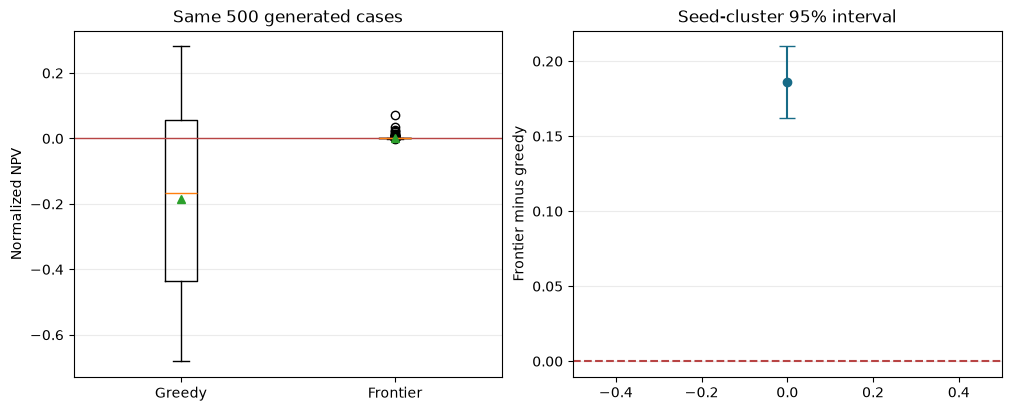

In [11]:
# Plot paired values and their frozen seed-cluster interval.
policy_npv = np.asarray([r["normalized_npv"] for r in synthetic])
greedy_npv = np.asarray([r["classical_normalized_npv"] for r in synthetic])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].boxplot([greedy_npv, policy_npv], tick_labels=["Greedy", "Frontier"], showmeans=True)
axes[0].axhline(0, color="#B84444", linewidth=1)
axes[0].set(ylabel="Normalized NPV", title="Same 500 generated cases")
axes[1].errorbar(
    [0],
    [paired.mean()],
    yerr=[[paired.mean() - paired_ci["lower"]], [paired_ci["upper"] - paired.mean()]],
    fmt="o",
    capsize=6,
    color="#176B87",
)
axes[1].axhline(0, color="#B84444", linestyle="--")
axes[1].set(xlim=(-0.5, 0.5), ylabel="Frontier minus greedy", title="Seed-cluster 95% interval")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()


The box plot confirms the policy's mass at zero and exposes the greedy negative tail. The paired interval is positive, but its interpretation is limited by near-zero policy coverage. It is an objective contrast under one generator, not a production-rate or field-safety claim.

## Comparison

The matched greedy baseline answers whether the policy improves the same value objective on the same generated graph. A positive mean difference can arise when one method returns zero and the other returns a negative schedule. The median policy NPV and coverage reveal this pattern: the test mean is positive while the typical policy result is empty. The product comparison adds methods with different search budgets. Their paired outcomes show where the frontier choice loses even though it stays feasible. Read each win count together with its denominator; do not pool heterogeneous case NPVs into a single percentage improvement.

In [12]:
# Count only paired product outcomes while preserving every failure row.
product = DATA["product_cases"]
methods = sorted({m["method"] for row in product for m in row["paired_baseline_methods"]})
comparison = []
for name in methods:
    values = [
        m["frontier_minus_baseline_npv"]
        for row in product
        for m in row["paired_baseline_methods"]
        if m["method"] == name
    ]
    comparison.append(
        {
            "method": name,
            "wins": sum(v > 0 for v in values),
            "paired_cases": len(values),
            "losses": sum(v < 0 for v in values),
        }
    )
failures = [{"case": r["case_id"], "reason": r["failure_reason"]} for r in product if r["status"] == "failed"]
print(
    {
        "statuses": {
            s: sum(r["status"] == s for r in product)
            for s in ("complete", "partial", "failed", "unavailable")
        },
        "comparisons": comparison,
        "failures": failures,
    }
)


{'statuses': {'complete': 0, 'partial': 11, 'failed': 2, 'unavailable': 0}, 'comparisons': [{'method': 'bench-by-bench', 'wins': 11, 'paired_cases': 11, 'losses': 0}, {'method': 'cpitD-local-search', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'exts-two-resource', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'learned-expected-time', 'wins': 2, 'paired_cases': 11, 'losses': 9}, {'method': 'nested-shells', 'wins': 9, 'paired_cases': 11, 'losses': 2}, {'method': 'shift-local-search', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'sliding-window', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'toposort-expected', 'wins': 0, 'paired_cases': 11, 'losses': 11}, {'method': 'toposort-gershon', 'wins': 8, 'paired_cases': 11, 'losses': 3}, {'method': 'toposort-greedy', 'wins': 9, 'paired_cases': 11, 'losses': 2}], 'failures': [{'case': 'ctrl-degenerate', 'reason': 'ValueError: frontier policy currently requires the declared two-resource CPIT contract

### Reading the product comparison

Each method bar uses the number of successful paired cases, not all thirteen. The two failed inputs remain in the status output and cannot be silently treated as zero wins. Greedy is beaten in most supported cases, while exact expected-time and several local-search methods beat the frontier policy in all eleven. No interval is drawn because this fixed case suite is not a random sample.

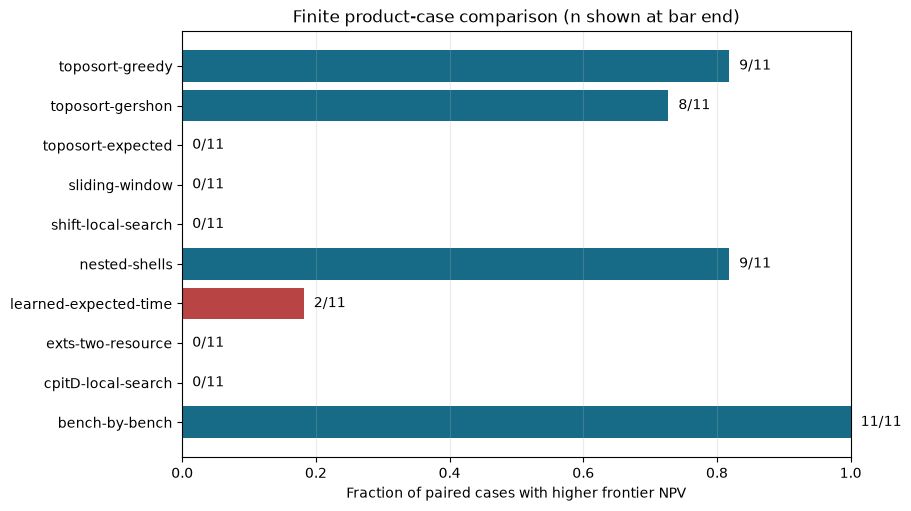

In [13]:
# Display paired win counts and their denominators for the fixed case suite.
labels = [row["method"] for row in comparison]
rates = [row["wins"] / row["paired_cases"] for row in comparison]
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
y = np.arange(len(labels))
ax.barh(y, rates, color=["#176B87" if value >= 0.5 else "#B84444" for value in rates])
ax.set(
    yticks=y,
    yticklabels=labels,
    xlim=(0, 1),
    xlabel="Fraction of paired cases with higher frontier NPV",
    title="Finite product-case comparison (n shown at bar end)",
)
for i, row in enumerate(comparison):
    ax.text(rates[i] + 0.015, i, f"{row['wins']}/{row['paired_cases']}", va="center")
ax.grid(axis="x", alpha=0.25)
plt.show()


The comparison separates the favorable greedy count from losses against stronger search. Its denominators range over the eleven supported cases. Because case economics and solver effort differ, the plot is not a universal method ranking and a count does not express the value size of a win.

## Evidence

The synthetic test gives the policy 500 feasible partial schedules, not 500 complete schedules. Its mean normalized NPV is 0.00084699 and its median is zero. The predeclared 95% seed-cluster interval for the mean is [0.00052501, 0.00127004]. The paired mean difference from greedy is 0.18618341 with interval [0.16181947, 0.20979947]. The code derives the empty-schedule count from all 500 assignments (277 cases, 55.4%); median tonnage and value coverage are both zero. The result is therefore negative for practical coverage under this frozen policy and generator, despite the favorable value-only contrast.

Product evaluation yields eleven feasible partial schedules and two failures. `ctrl-degenerate` uses one resource, while the current adapter requires the declared two-resource input; `zuck-small-declared` does not supply a source-backed grade vector. Among the eleven paired rows, wins are 11/11 for bench-by-bench, 9/11 for nested-shells, 9/11 for greedy, 8/11 for Gershon, and 2/11 for learned expected-time. The policy records 0/11 against exact expected-time ordering, sliding-window, shift-local-search, and C-PIT[D] local search. These findings describe this finite set and do not estimate a population rate.

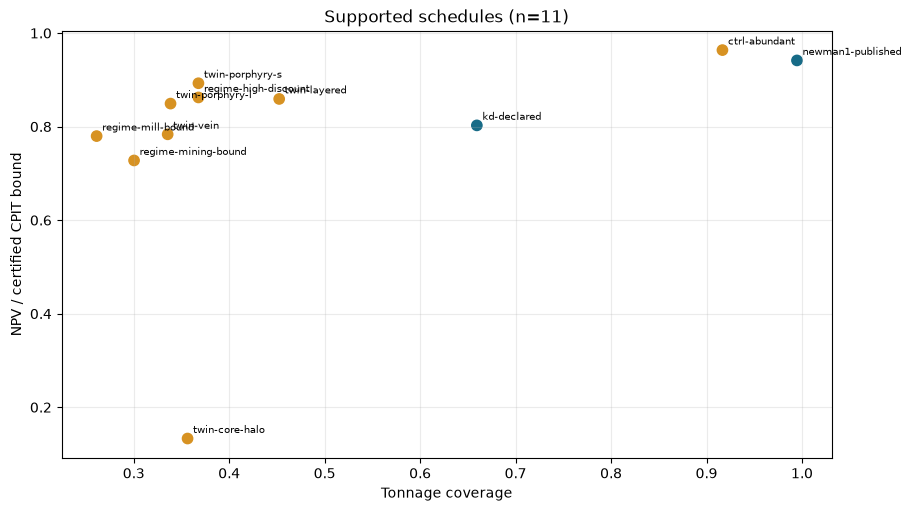

In [14]:
# Plot bound-normalized NPV against coverage; mark unsupported inputs without inventing scores.
supported = [r for r in product if r["status"] in ("complete", "partial") and r["certified_bound"]]
failed = [r for r in product if r["status"] == "failed"]
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
x = [r["tonnage_coverage"] for r in supported]
y = [r["npv"] / r["certified_bound"] for r in supported]
ax.scatter(x, y, c=["#176B87" if r["source"] == "licensed-minelib" else "#D79222" for r in supported], s=55)
for r in supported:
    ax.annotate(
        r["case_id"],
        (r["tonnage_coverage"], r["npv"] / r["certified_bound"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
    )
ax.set(xlabel="Tonnage coverage", ylabel="NPV / certified CPIT bound", title="Supported schedules (n=11)")
ax.grid(alpha=0.25)
plt.show()


The scatter contains only eleven scored cases; failed inputs have no coordinate and are not drawn at the origin. The case IDs are available in the printed table. The bound ratio and coverage summarize different dimensions and omit operational constraints.

### Sensitivity and limits

All 500 held-out graphs belong to the previously reserved funnel family, so this test cannot estimate differences across graph families. Instead, the code divides the registered size range into four empirical quartiles and reports each quartile’s case count, size range, mean NPV, mean positive-value coverage, and empty-schedule fraction. This post-access description asks whether outcome degradation varies with graph size; it is not a confirmatory subgroup test. It is descriptive because the frozen policy and generator are fixed; inspecting these groups after test access cannot justify tuning a new threshold and then reusing the same sample as independent confirmation. Preserve the original result before any exploratory filter and keep all attempted seeds visible.

All 500 held-out graphs belong to the previously reserved funnel family, so this test cannot estimate differences across graph families. Instead, the code divides the registered size range into four empirical quartiles and reports each quartile’s case count, size range, mean NPV, mean positive-value coverage, and empty-schedule fraction. This post-access description asks whether outcome degradation varies with graph size; it is not a confirmatory subgroup test. It is descriptive because the frozen policy and generator are fixed; inspecting these groups after test access cannot justify tuning a new threshold and then reusing the same sample as independent confirmation. Preserve the original result before any exploratory filter and keep all attempted seeds visible.

The three figures answer different questions. The first plots paired test values and highlights the zero-action mass. It shows whether the mean difference is driven by a broad shift or by a baseline tail; it does not imply field performance. The second compares product-case win counts and makes the denominator visible. It excludes only cases where the policy failed before producing a comparable schedule, while those failures stay in the full thirteen-case table. The third relates bound-normalized NPV to coverage for each supported product case. The bound ratio gives cases with different dollar scales a common vertical reference; it does not make their economics identical. Failed cases are marked separately because no performance score exists for them.

The completed funnel-family test does not include a stop-only ablation, component removals, or a second frozen ensemble. It cannot identify which architecture component caused abstention. Its size-quartile summaries do not substitute for a planned family-transfer study. The full training design uses other precedence families, but the held-out outcome set contains only funnel graphs and simplified economic/resource rules. It does not represent drillhole uncertainty, geotechnical reconciliation, fleet dispatch, stockpile flow, plant variability, or operator constraints. The thirteen registered product cases add mathematical benchmark context, but two are unsupported and the remaining cases are a finite set. A schedule passing the encoded validator is not an operating plan. Any model, feature, or training change after observing these outputs requires a new protocol and untouched test split.

In [15]:
# Compare the frozen policy by empirical graph-size quartile, not by family.
sizes = np.asarray([r["size"] for r in synthetic], dtype=int)
cutpoints = np.quantile(sizes, [0.25, 0.50, 0.75])
size_groups = np.digitize(sizes, cutpoints, right=True)
size_rows = []
for group in range(4):
    rows = [r for r, label in zip(synthetic, size_groups, strict=True) if label == group]
    size_rows.append(
        {
            "quartile": group + 1,
            "cases": len(rows),
            "size_min": min(r["size"] for r in rows),
            "size_max": max(r["size"] for r in rows),
            "mean_npv": float(np.mean([r["normalized_npv"] for r in rows])),
            "mean_value_coverage": float(np.mean([r["positive_value_coverage"] for r in rows])),
            "empty_fraction": float(np.mean([r["assignments"] == 0 for r in rows])),
        }
    )
print({"families": sorted({r["family"] for r in synthetic}), "size_quartiles": size_rows})


{'families': ['funnel'], 'size_quartiles': [{'quartile': 1, 'cases': 125, 'size_min': 32, 'size_max': 2059, 'mean_npv': 0.002622018040063465, 'mean_value_coverage': 0.006589691531303815, 'empty_fraction': 0.536}, {'quartile': 2, 'cases': 125, 'size_min': 2076, 'size_max': 4103, 'mean_npv': 0.0002885324032298698, 'mean_value_coverage': 0.0007835866707489523, 'empty_fraction': 0.584}, {'quartile': 3, 'cases': 125, 'size_min': 4120, 'size_max': 6147, 'mean_npv': 0.00029839124471916795, 'mean_value_coverage': 0.0006836100845516171, 'empty_fraction': 0.512}, {'quartile': 4, 'cases': 125, 'size_min': 6164, 'size_max': 8192, 'mean_npv': 0.00017902058780674553, 'mean_value_coverage': 0.0003888817448277976, 'empty_fraction': 0.584}]}


Each quartile row reports the group size and outcome summaries. The separate plot keeps empty schedules visible alongside mean value.

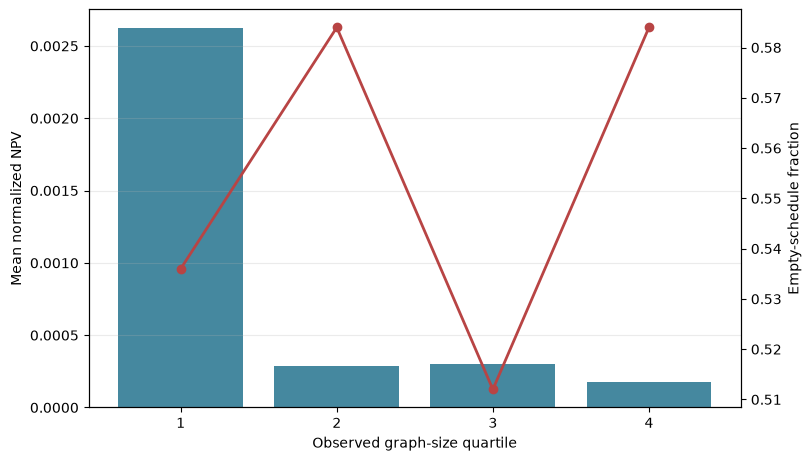

In [16]:
# Plot quartile means and empty-schedule fractions on separate scales.
quartiles = [row["quartile"] for row in size_rows]
mean_npv = [row["mean_npv"] for row in size_rows]
empty_fraction = [row["empty_fraction"] for row in size_rows]
fig, left = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
left.bar(quartiles, mean_npv, color="#176B87", alpha=0.8)
left.set(xlabel="Observed graph-size quartile", ylabel="Mean normalized NPV")
right = left.twinx()
right.plot(quartiles, empty_fraction, color="#B84444", marker="o", linewidth=2)
right.set_ylabel("Empty-schedule fraction")
left.set_xticks(quartiles)
left.grid(axis="y", alpha=0.25)
plt.show()


Size quartiles expose post-access heterogeneity without changing the frozen policy. A weak size-specific result is descriptive, not permission to retune on these test cases. The interval above remains clustered by seed; these slices are not new confirmatory tests under the frozen evaluation design.

### Use the analysis on your own data

Begin with one immutable row per independent synthetic seed or benchmark case. Preserve an opaque case identifier, source family, graph size, split, method status, objective units, assignment count, both coverage fractions, baseline objective, source digest, feature-contract digest, selected-checkpoint digest, and evaluator version. Record a failure reason when a policy does not produce a schedule. Never encode failure as NPV zero: zero is a measured empty schedule, while failure means the objective was not available. Keep restricted block identifiers and MineLib period assignments outside a public summary.

Begin with one immutable row per independent synthetic seed or benchmark case. Preserve an opaque case identifier, source family, graph size, split, method status, objective units, assignment count, both coverage fractions, baseline objective, source digest, feature-contract digest, selected checkpoint digest, and evaluator version. Record a failure reason when a policy does not produce a schedule. Never encode failure as an NPV of zero: zero is a measured empty schedule, while failure means the objective was not available. Keep restricted block identifiers and MineLib period assignments outside a public summary.

The repository API `summarize_case_rows` accepts rows with `seed`, `normalized_npv`, `positive_value_coverage`, and `assigned_blocks`. It rejects missing fields, duplicate seeds, non-finite metrics, out-of-range coverage, and negative assignment counts. The API `seed_clustered_interval` accepts the full case rows, a metric name, replicate count, and RNG seed; it retains only feasible complete or partial results with valid seed IDs and computes the declared cluster bootstrap. For a new experiment, freeze those settings before test access, keep all failures in the run receipt, and report how many rows entered each paired contrast.

Before calculating summaries, reconcile case IDs to the frozen manifest and confirm that paired methods share the same instance digest and objective. Recompute feasibility and NPV from the canonical schedule in a controlled environment before exporting aggregates. Check status counts against retained rows, verify receipt hashes, and ensure that licensed inputs contain no block-level vectors. Use descriptive plots for fixed benchmark cases and reserve confidence intervals for the independent sampling unit actually specified by the experiment. This lesson demonstrates analysis of the current frozen study; it does not authorize a new evaluation protocol or make a user-supplied dataset comparable without matching units and constraints.

In [17]:
# Define a compact caller-owned fixture with measured empty and negative outcomes.
own_fields = ("seed", "status", "feasible", "normalized_npv", "positive_value_coverage", "assigned_blocks")
own_values = [
    (8101, "partial", True, 0.04, 0.12, 3),
    (8102, "partial", True, 0.00, 0.00, 0),
    (8103, "complete", True, 0.09, 0.35, 7),
    (8104, "partial", True, -0.01, 0.02, 1),
]
own_rows = [dict(zip(own_fields, values, strict=True)) for values in own_values]


Pass the four rows through the same summary and seed-cluster APIs used above. The interval is a mechanics example only: four observations do not support a useful scientific uncertainty estimate.

In [18]:
# Summarize the caller fixture and compute its declared cluster interval.
own_summary = summarize_case_rows(own_rows)
own_interval = seed_clustered_interval(own_rows, metric="normalized_npv", replicates=2000, seed=118)
print({"illustrative_rows": len(own_rows), "summary": own_summary, "interval": own_interval})


{'illustrative_rows': 4, 'summary': {'cases': 4, 'nonempty_fraction': 0.75, 'mean_assigned_blocks': 2.75, 'mean_npv': 0.03, 'median_npv': 0.02, 'median_value_coverage': 0.06999999999999999, 'minimum_npv': -0.01, 'maximum_npv': 0.09}, 'interval': {'metric': 'normalized_npv', 'unit': 'seed-cluster', 'clusters': 4, 'replicates': 2000, 'rng_seed': 118, 'confidence_level': 0.95, 'lower': -0.005, 'upper': 0.0675}}


This independent four-row fixture demonstrates the caller contract; it is not a slice of the opened test. For an actual dataset, validate every row against its frozen manifest and provenance, retain failed and unavailable cases in the receipt, and reserve untouched clusters for confirmation. Four rows are far too few for scientific inference.

## Results

**Answer:** No. The positive paired mean does not show useful schedules: 277 of 500 are empty, median NPV and coverage are zero, and several stronger product comparators win all eleven paired cases.

The analysis answers the question narrowly. The paired difference is positive, yet the typical synthetic policy schedule assigns zero blocks and carries zero value coverage. On product cases, the policy wins against the simplest greedy constructor in nine of eleven supported rows and loses every case against several stronger ordering and local-search baselines. Two inputs fail closed. Feasibility is a software property; useful coverage and comparative value are empirical properties, and they point in a different direction here.

The figures do not establish causation for any policy component, robustness to a changed generator, or transfer to a mine. The bootstrap interval covers seed variation in this frozen synthetic design only. The product win counts summarize the named thirteen-case suite and have no sampling interpretation. Runtime is inference time on this machine configuration, not an end-to-end training cost or universal speed claim. These limits are part of the result, not footnotes to omit when presenting the numbers.

## Summary

A defensible analysis keeps the full denominator, computes uncertainty at the seed level, and interprets paired objective together with assignments and coverage. This study's positive greedy difference coexists with zero median NPV and coverage because the policy often abstains. Product comparisons show that feasibility does not overcome losses to methods with stronger search. Preserve the two failed inputs, distinguish the completed sample from the consumed attempts, and do not turn the finite benchmark into a general claim. The current result is a reproducible low-coverage diagnostic; the application remains closed to this replay until a complete rebake and release review are finished.

## References

1. Teichteil-Königsbuch et al., graph neural policies for resource-constrained scheduling, ICAPS 2023, https://doi.org/10.1609/icaps.v33i1.27244
2. Lambert et al., open-pit block-sequencing formulations tutorial, https://doi.org/10.1287/inte.2013.0731
3. Schulman et al., proximal policy optimization, https://arxiv.org/abs/1707.06347
4. PhaseFlow source, contracts, and evaluation code, https://github.com/fsantibanezleal/CAOS_PhaseFlow